# 04 - Risk Management & Final Strategy

Add volatility targeting and stop-outs to the baseline z-score strategy.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

NOTEBOOK_DIR = Path().resolve()
CANDIDATES = [NOTEBOOK_DIR, NOTEBOOK_DIR.parent, NOTEBOOK_DIR.parent.parent]
PROJECT_ROOT = None
for candidate in CANDIDATES:
    if (candidate / 'src' / '__init__.py').exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise RuntimeError('Unable to locate project root containing src/__init__.py')

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.preprocess import load_processed_ohlcv, chronological_train_test_split
from src.signals import rolling_zscore_signal
from src.backtest import run_backtest_with_costs
from src.metrics import sharpe_ratio, max_drawdown, trade_count

plt.style.use('seaborn-v0_8')

## Load processed data

In [2]:
DATA_PATH = PROJECT_ROOT / 'data/processed/btcusdt_5m.parquet'

df = load_processed_ohlcv(DATA_PATH)
print(f'Rows: {len(df):,} from {df.index.min()} to {df.index.max()}')
df.head()

Rows: 105,407 from 2024-01-01 00:05:00+00:00 to 2024-12-31 23:55:00+00:00


,open,high,low,close,volume,return,log_return
timestamp,,,,,,,
2024-01-01 00:05:00+00:00,42397.22,42432.74,42385.26,42409.96,141.311,0.000300,0.000300
2024-01-01 00:10:00+00:00,42409.97,42488.09,42409.96,42488.00,135.143,0.001840,0.001838
2024-01-01 00:15:00+00:00,42488.00,42554.57,42458.58,42458.85,163.324,-0.000686,-0.000686
2024-01-01 00:20:00+00:00,42458.85,42491.10,42445.84,42473.93,117.272,0.000355,0.000355
2024-01-01 00:25:00+00:00,42473.93,42500.00,42412.02,42419.73,111.651,-0.001276,-0.001277


## Train / test split

In [3]:
TRAIN_FRACTION = 0.7

df_train, df_test = chronological_train_test_split(df, train_fraction=TRAIN_FRACTION)
print(f'Train rows: {len(df_train):,}')
print(f'Test rows: {len(df_test):,}')

Train rows: 73,785
Test rows: 31,622


## Baseline parameters

In [4]:
WINDOW = 20
Z_ENTRY = 1.5
COST_PER_UNIT = 0.0005

## Baseline backtest with costs (no overlays)

In [5]:
def run_variant(df_split, label, **kwargs):
    df_sig = rolling_zscore_signal(df_split, window=WINDOW, z_entry=Z_ENTRY)
    bt = run_backtest_with_costs(
        df_sig,
        cost_per_unit_change=COST_PER_UNIT,
        **kwargs,
    )
    df_bt = bt.df
    stats = {
        'variant': label,
        'sharpe': sharpe_ratio(df_bt['strategy_return_net']),
        'max_dd': max_drawdown(df_bt['equity_curve_net']),
        'trades': trade_count(df_bt['position']),
        'total_return': df_bt['equity_curve_net'].iloc[-1] - 1.0,
        'total_cost': bt.extras.get('total_cost', 0.0),
        'equity': df_bt['equity_curve_net'],
    }
    return stats

train_baseline = run_variant(df_train, 'baseline')
test_baseline = run_variant(df_test, 'baseline')
print(train_baseline['sharpe'], train_baseline['max_dd'], train_baseline['trades'])

-47.08129493967313 -0.9998461877552048 16768


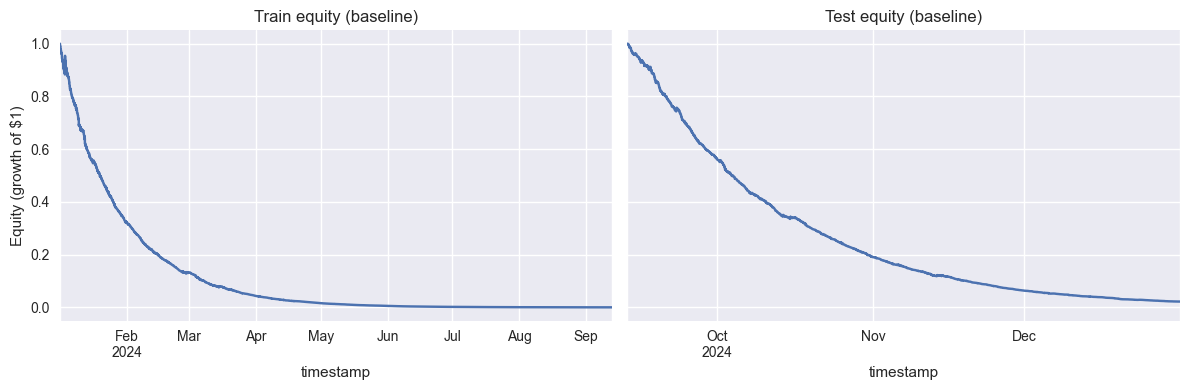

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
train_baseline['equity'].plot(ax=axes[0], title='Train equity (baseline)')
axes[0].grid(True)
axes[0].set_ylabel('Equity (growth of $1)')
test_baseline['equity'].plot(ax=axes[1], title='Test equity (baseline)')
axes[1].grid(True)
plt.tight_layout()
plt.show()

## Add volatility targeting

In [7]:
RISK_PARAMS_VOL = {
    'max_position_size': 1.5,
    'target_volatility': 0.003,
    'volatility_lookback': 96,
    'max_leverage': 1.5,
}
train_vol = run_variant(df_train, 'vol_target', **RISK_PARAMS_VOL)
test_vol = run_variant(df_test, 'vol_target', **RISK_PARAMS_VOL)

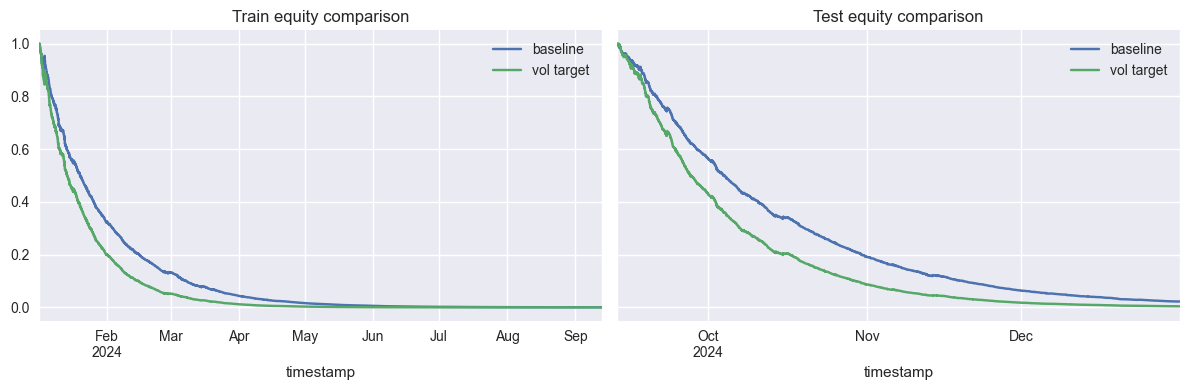

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
train_baseline['equity'].plot(ax=axes[0], label='baseline')
train_vol['equity'].plot(ax=axes[0], label='vol target')
axes[0].legend()
axes[0].grid(True)
axes[0].set_title('Train equity comparison')
test_baseline['equity'].plot(ax=axes[1], label='baseline')
test_vol['equity'].plot(ax=axes[1], label='vol target')
axes[1].legend()
axes[1].grid(True)
axes[1].set_title('Test equity comparison')
plt.tight_layout()
plt.show()

## Add daily stop-out on top of volatility scaling

In [9]:
RISK_PARAMS_VOL_STOP = dict(RISK_PARAMS_VOL, daily_stop_loss=0.01)
train_vol_stop = run_variant(df_train, 'vol_target_stop', **RISK_PARAMS_VOL_STOP)
test_vol_stop = run_variant(df_test, 'vol_target_stop', **RISK_PARAMS_VOL_STOP)

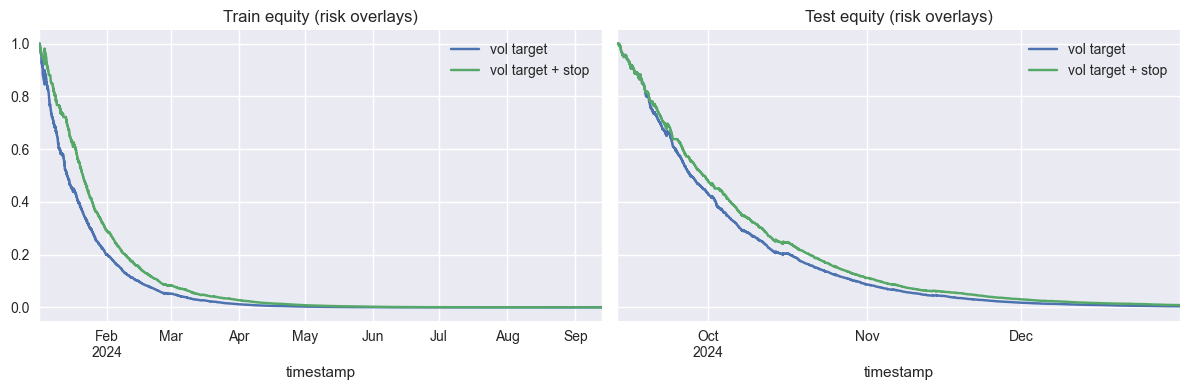

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
train_vol['equity'].plot(ax=axes[0], label='vol target')
train_vol_stop['equity'].plot(ax=axes[0], label='vol target + stop')
axes[0].legend()
axes[0].grid(True)
axes[0].set_title('Train equity (risk overlays)')
test_vol['equity'].plot(ax=axes[1], label='vol target')
test_vol_stop['equity'].plot(ax=axes[1], label='vol target + stop')
axes[1].legend()
axes[1].grid(True)
axes[1].set_title('Test equity (risk overlays)')
plt.tight_layout()
plt.show()

## Variant comparison table

In [11]:
import pandas as pd
variants = [
    ('baseline', train_baseline, test_baseline),
    ('vol_target', train_vol, test_vol),
    ('vol_target_stop', train_vol_stop, test_vol_stop),
]
rows = []
for name, train_stats, test_stats in variants:
    rows.append({
        'variant': name,
        'split': 'train',
        'sharpe': train_stats['sharpe'],
        'max_dd': train_stats['max_dd'],
        'trades': train_stats['trades'],
        'total_cost': train_stats['total_cost'],
    })
    rows.append({
        'variant': name,
        'split': 'test',
        'sharpe': test_stats['sharpe'],
        'max_dd': test_stats['max_dd'],
        'trades': test_stats['trades'],
        'total_cost': test_stats['total_cost'],
    })
comparison = pd.DataFrame(rows)
comparison

,variant,split,sharpe,max_dd,trades,total_cost
0,baseline,train,-47.081295,-0.999846,16768,8.822000
1,baseline,test,-55.728022,-0.977983,7314,3.839000
2,vol_target,train,-54.003627,-0.999997,16911,12.720594
3,vol_target,test,-58.512116,-0.996055,7340,5.608983
4,vol_target_stop,train,-51.199849,-0.999974,14110,10.676683
5,vol_target_stop,test,-54.951679,-0.991463,6395,4.910657


## Final summary

In [12]:
print('Version 1.0 strategy: window=20, z=1.5, cost=0.0005, volatility target 0.3%, daily stop 1%.')
print('Train Sharpe (net):', train_vol_stop['sharpe'])
print('Test Sharpe (net):', test_vol_stop['sharpe'])
print('Test max DD (net):', test_vol_stop['max_dd'])
print('Test trades:', test_vol_stop['trades'])

Version 1.0 strategy: window=20, z=1.5, cost=0.0005, volatility target 0.3%, daily stop 1%.
Train Sharpe (net): -51.19984853474775
Test Sharpe (net): -54.95167858151697
Test max DD (net): -0.9914629118349578
Test trades: 6395


### Takeaways
- Costs dominate: even with overlays, Sharpe stays deeply negative.
- Volatility targeting + daily stop reduce turnover/drawdowns but cannot rescue profitability.
- Treat this as a risk-managed research prototype, not a production-ready trading system.